# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import LarchCasebearerTreeClassificationDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv 

## Visualize images and objects witn bounding boxes

Total number of patches: 1533


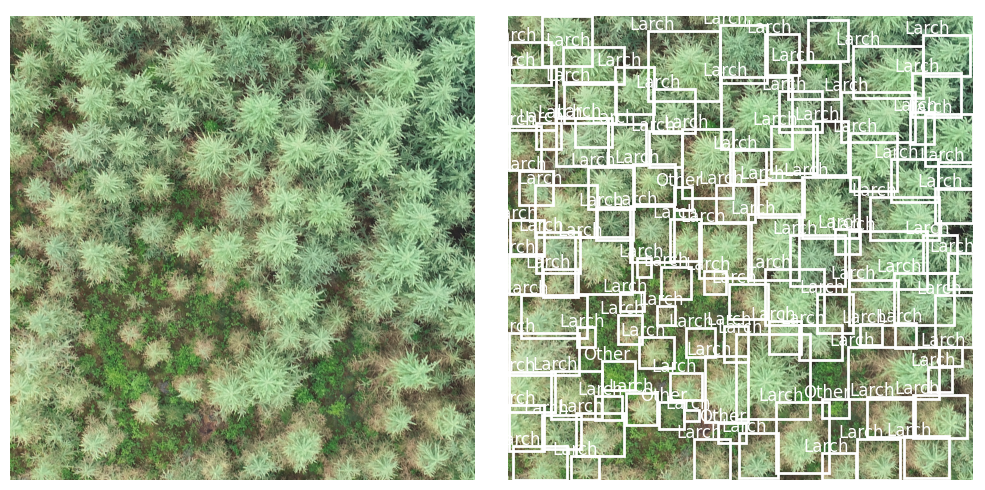

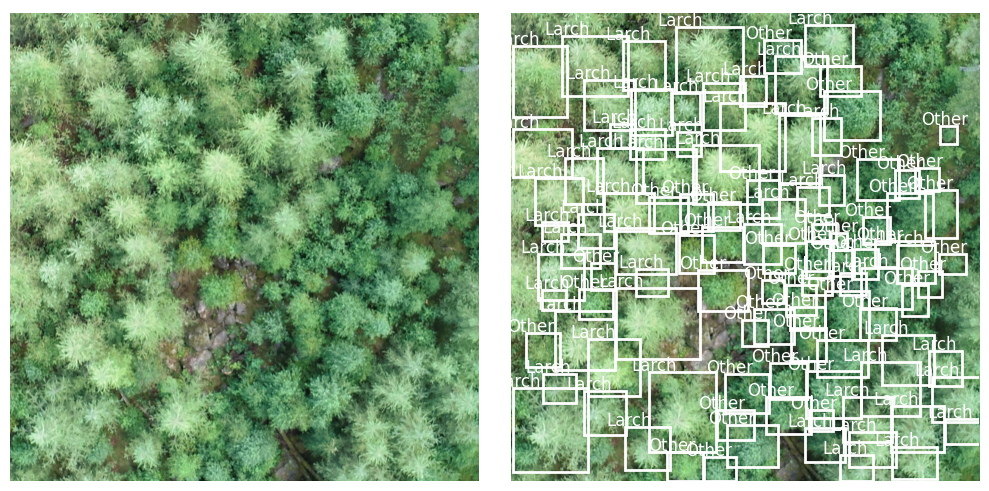

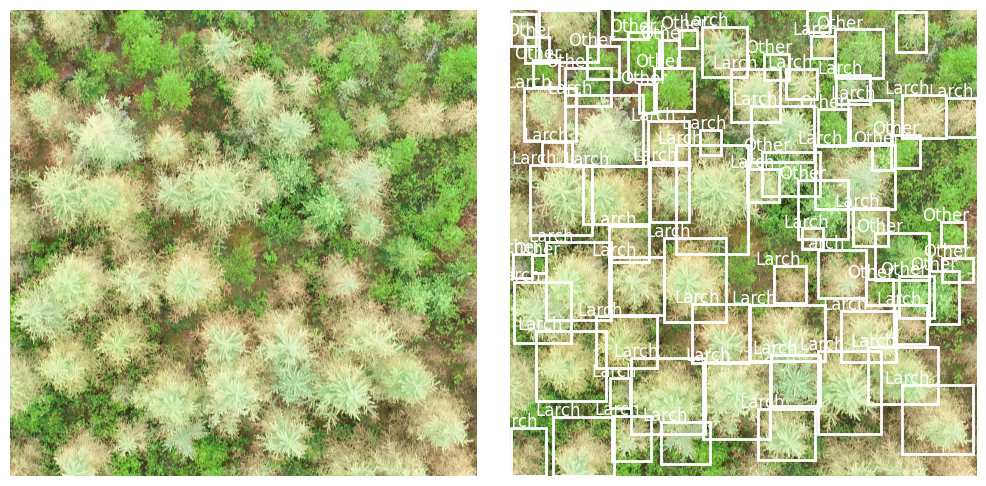

In [ ]:
dataset_config = {
    "image_dir": "./data/larch_casebearer/images/",
    "annotations_dir": "./data/larch_casebearer/annotations/",
}
dataset = LarchCasebearerTreeClassificationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(30);
dataset.show_image(90);

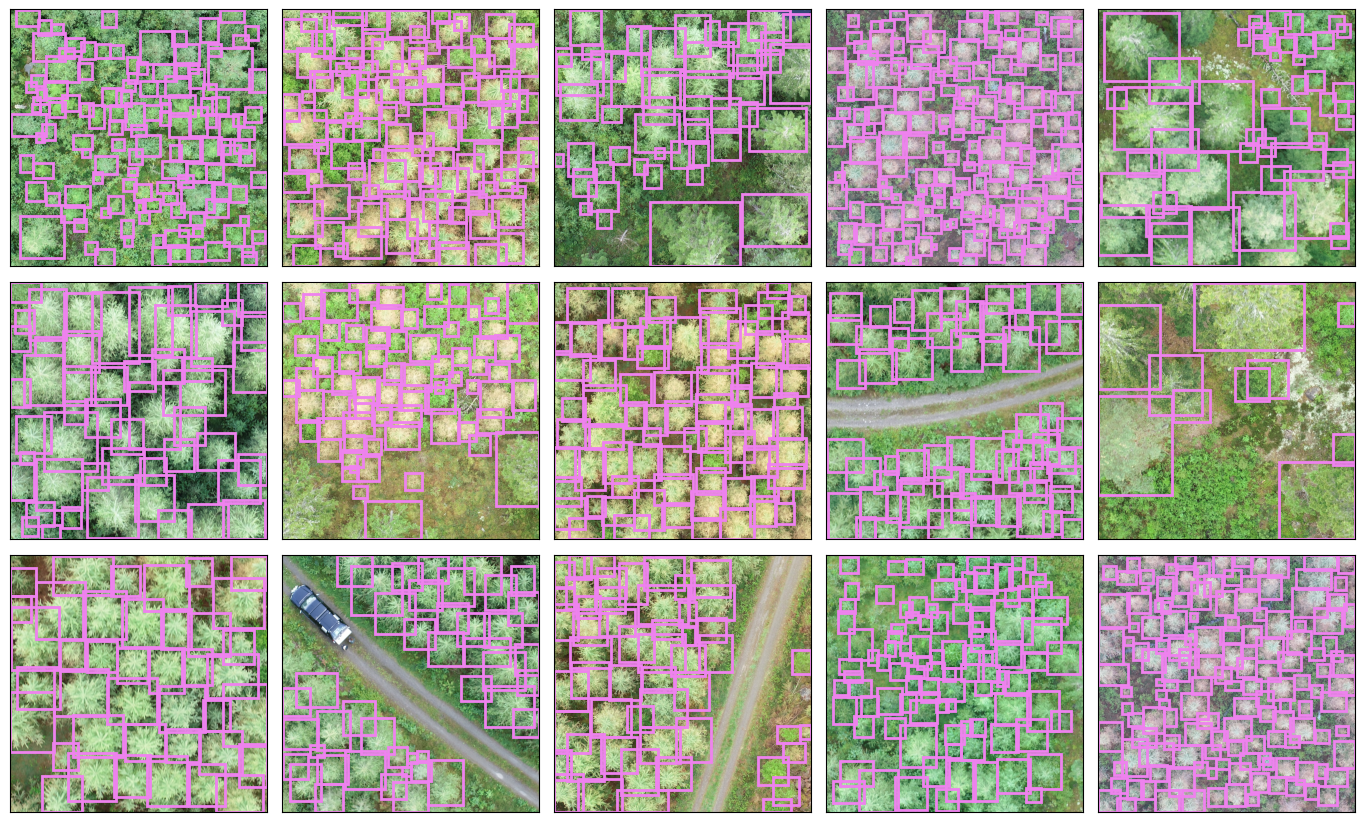

In [51]:
dataset.show_batch(15);

In [52]:
dataset.data_distribution_table()

,Label,Count
0,Other,24689
1,Larch,77142


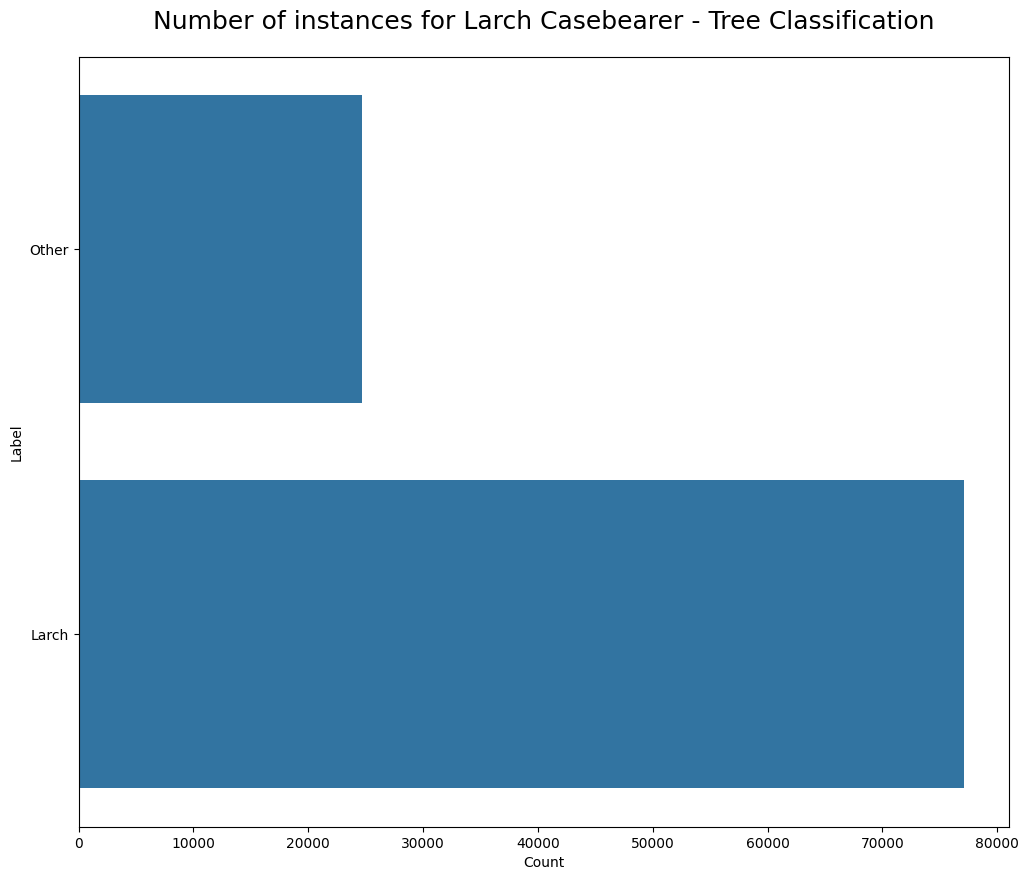

In [53]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "image_dir": "./data/larch_casebearer/images/",
    "annotations_dir": "./data/larch_casebearer/annotations/",
    "csv_file": "./data/larch_casebearer/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = LarchCasebearerTreeClassificationDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1228


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/larch_casebearer/experiments/"
model_config = {
    "num_classes": 3, #include the background class
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [16]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-22 12:56:13,229 INFO Starting training.
training: 100%|██████████| 154/154 [00:53<00:00,  2.87it/s]
2025-05-22 12:57:06,912 INFO epoch: 1, time: 53, loss:  0.65545
testing on train set: 100%|██████████| 154/154 [00:38<00:00,  3.96it/s]
2025-05-22 12:59:46,504 INFO map:0.47676047682762146, map_50:0.7963739037513733, map_75:0.5271815061569214, map_small:0.2915385663509369, map_medium:0.5242083668708801, map_large:0.6658066511154175, mar_1:0.024755731225013733, mar_10:0.1793804168701172, mar_100:0.5666532516479492, mar_small:0.39610162377357483, mar_medium:0.6139947772026062, mar_large:0.7482649683952332, map_per_class:tensor(0.5583), tensor(0.3952), mar_100_per_class:tensor(0.6293), tensor(0.5040), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)
training: 100%|██████████| 154/154 [00:53<00:00,  2.87it/s]
2025-05-22 13:00:40,145 INFO epoch: 2, time: 54, loss:  0.58349
testing on train set: 100%|██████████| 154/154 [00:40<00:00,  3.85it/s]
2025-05-22 13:03:19,643

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "./data/larch_casebearer/images/",
    "annotations_dir": "./data/larch_casebearer/annotations/",
    "csv_file": "./data/larch_casebearer/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = LarchCasebearerTreeClassificationDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/larch_casebearer/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 153


2025-05-22 13:30:58,335 INFO Loading checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/checkpoint.pth.tar
2025-05-22 13:30:58,719 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 20/20 [00:05<00:00,  3.43it/s]


[{'map': 0.4543115496635437,
  'map_50': 0.7426887154579163,
  'map_75': 0.5142272710800171,
  'map_small': 0.2771959602832794,
  'map_medium': 0.5088481903076172,
  'map_large': 0.6503400802612305,
  'mar_1': 0.022542834281921387,
  'mar_10': 0.16473810374736786,
  'mar_100': 0.5382552742958069,
  'mar_small': 0.37696272134780884,
  'mar_medium': 0.593112587928772,
  'mar_large': 0.7192032933235168,
  'map_per_class': [tensor(0.5737), tensor(0.3350)],
  'mar_100_per_class': [tensor(0.6366), tensor(0.4400)],
  'classes': [tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)]}]

## Predictions

2025-05-22 13:31:18,405 INFO Loading checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/checkpoint.pth.tar
2025-05-22 13:31:18,748 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/checkpoint.pth.tar at epoch 11


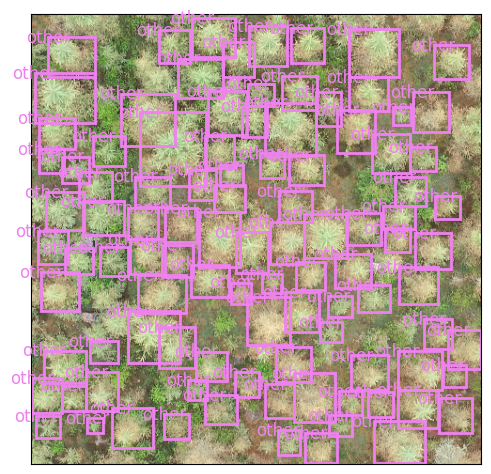

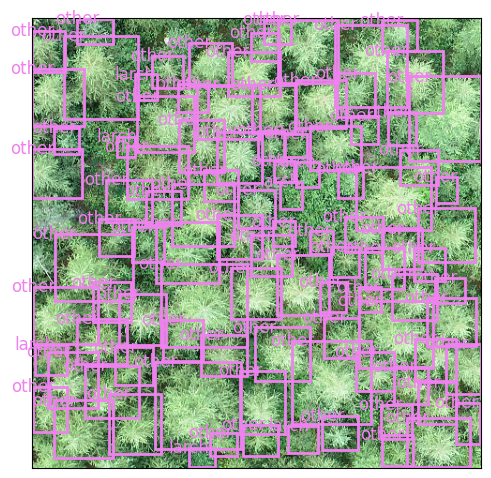

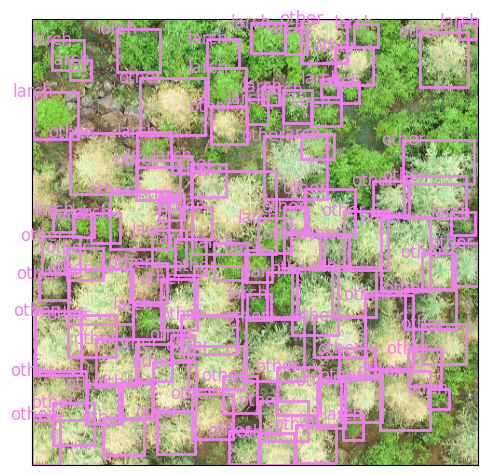

In [ ]:
model_config = {
    "num_classes": 3,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/larch_casebearer/experiments/checkpoint.pth.tar"
labels = ['no-data','other','larch']
transform = Resize()
model.load_model(model_path)

csv_file = "./data/larch_casebearer/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/larch_casebearer/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/larch_casebearer/' + test_list[10])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/larch_casebearer/' + test_list[20])
fig = model.detect_objects(image, labels, transform)